In [4]:
import pandas as pd
from pathlib import Path

path = Path("C:/Users/VICTUS/OneDrive/Documents/olist-ecommerce-analysis/Data/Raw data")

date_cols = ["order_purchase_timestamp", "order_approved_at",
             "order_delivered_carrier_date", "order_delivered_customer_date",
             "order_estimated_delivery_date"]

orders = pd.read_csv(path / "olist_orders_dataset.csv", parse_dates=date_cols)
items       = pd.read_csv(path / "olist_order_items_dataset.csv")
customers   = pd.read_csv(path / "olist_customers_dataset.csv")
products    = pd.read_csv(path / "olist_products_dataset.csv")
reviews     = pd.read_csv(path / "olist_order_reviews_dataset.csv",
                          parse_dates=["review_creation_date", "review_answer_timestamp"])
translation = pd.read_csv(path / "product_category_name_translation.csv")

for name, df in [("orders",orders),("items",items),("customers",customers),("products",products),("reviews",reviews)]:
    print(name, df.shape,"duplicated_data:",df.duplicated().sum())

print(orders.isna().sum())
print(orders["order_status"].value_counts())


orders (99441, 8) duplicated_data: 0
items (112650, 7) duplicated_data: 0
customers (99441, 5) duplicated_data: 0
products (32951, 9) duplicated_data: 0
reviews (99224, 7) duplicated_data: 0
order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64
order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64


In [6]:
#clean
products = pd.read_csv(path / "olist_products_dataset.csv")
products=products.merge(translation, on="product_category_name", how='left')
products["catagory"]=(products["product_category_name_english"].fillna(products["product_category_name"]).fillna("unkown"))
print(products["catagory"].head(20))

0                     perfumery
1                           art
2                sports_leisure
3                          baby
4                    housewares
5           musical_instruments
6                    cool_stuff
7               furniture_decor
8               home_appliances
9                          toys
10               bed_bath_table
11                         baby
12          musical_instruments
13              furniture_decor
14    construction_tools_safety
15               sports_leisure
16                    perfumery
17        computers_accessories
18              furniture_decor
19               bed_bath_table
Name: catagory, dtype: object


In [7]:
#reviews
reviews =(reviews.sort_values("review_answer_timestamp")
          .drop_duplicates("order_id", keep='last'))
print(reviews)

                              review_id                          order_id  \
37547  6916ca4502d6d3bfd39818759d55d536  bfbd0f9bdef84302105ad712db648a6c   
5503   49f695dffa457eaba90d388a5c37e942  e5215415bb6f76fe3b7cb68103a0d1c0   
60439  743d98b1a4782f0646898fc915ef002a  e2144124f98f3bf46939bc5183104041   
28075  53752edb26544dd41c1209f582c9c589  b8b9d7046c083150cb5360b83a8ebb51   
41042  b2d5d8db2a841d27a72e4c06c6212368  9aa3197e4887919fde0307fc23601d7a   
...                                 ...                               ...   
46904  6c50d16eb583d5db7e841b77e89b7045  0b223d92c27432930dfe407c6aea3041   
14687  abf08328d2f1f0e8a33eee9f52f502f6  99e4a1f9377bf28f08f54a2eecccbf0d   
92802  6c883909cf53725a13caf477a70f00a4  7ce4e38f4eadd993bb5b2e60bb7f7bec   
49615  728d5cfdc7283cfd0a8061d7581a19f8  7e8072dc0f35ebb0c1b2a4743e0f179a   
80582  13548d0f62b03a0d3cb6efc00877fa13  30a2f24dd6770c91faa6b3481319204b   

       review_score review_comment_title  \
37547             1            

In [8]:
order_rev = (items.groupby("order_id")
                  .agg(revenue=("price", "sum"),
                       freight=("freight_value", "sum"),
                       n_items=("order_item_id", "count"))
                  .reset_index())
print(order_rev.head(20))

                            order_id  revenue  freight  n_items
0   00010242fe8c5a6d1ba2dd792cb16214    58.90    13.29        1
1   00018f77f2f0320c557190d7a144bdd3   239.90    19.93        1
2   000229ec398224ef6ca0657da4fc703e   199.00    17.87        1
3   00024acbcdf0a6daa1e931b038114c75    12.99    12.79        1
4   00042b26cf59d7ce69dfabb4e55b4fd9   199.90    18.14        1
5   00048cc3ae777c65dbb7d2a0634bc1ea    21.90    12.69        1
6   00054e8431b9d7675808bcb819fb4a32    19.90    11.85        1
7   000576fe39319847cbb9d288c5617fa6   810.00    70.75        1
8   0005a1a1728c9d785b8e2b08b904576c   145.95    11.65        1
9   0005f50442cb953dcd1d21e1fb923495    53.99    11.40        1
10  00061f2a7bc09da83e415a52dc8a4af1    59.99     8.88        1
11  00063b381e2406b52ad429470734ebd5    45.00    12.98        1
12  0006ec9db01a64e59a68b2c340bf65a7    74.00    23.32        1
13  0008288aa423d2a3f00fcb17cd7d8719    99.80    26.74        2
14  0009792311464db532ff765bf7b182ae    

In [9]:
import pandas as pd
from pathlib import Path

path = Path("C:/Users/VICTUS/OneDrive/Documents/olist-ecommerce-analysis/Data/Raw data")

date_cols = ["order_purchase_timestamp", "order_approved_at",
             "order_delivered_carrier_date", "order_delivered_customer_date",
             "order_estimated_delivery_date"]

orders = pd.read_csv(path / "olist_orders_dataset.csv", parse_dates=date_cols)
items       = pd.read_csv(path / "olist_order_items_dataset.csv")
customers   = pd.read_csv(path / "olist_customers_dataset.csv")
products    = pd.read_csv(path / "olist_products_dataset.csv")
reviews     = pd.read_csv(path / "olist_order_reviews_dataset.csv",
                          parse_dates=["review_creation_date", "review_answer_timestamp"])
translation = pd.read_csv(path / "product_category_name_translation.csv")
order_rev = (items.groupby("order_id")
                  .agg(revenue=("price", "sum"),
                       freight=("freight_value", "sum"),
                       n_items=("order_item_id", "count"))
                  .reset_index())

df = orders[orders['order_status']== 'delivered']. copy()
df = df.dropna(subset=["order_delivered_customer_date"])
purchase  = df["order_purchase_timestamp"].dt.normalize()
delivered = df["order_delivered_customer_date"].dt.normalize()
estimated = df["order_estimated_delivery_date"].dt.normalize()
df["order_month"] = df["order_purchase_timestamp"].dt.to_period('M') .astype(str)
df["delivered_day"]= (delivered - purchase) .dt.days
df["late_delivered"]= (delivered > estimated)
df["late_day"] = (delivered -estimated) .dt.days.clip(lower=0)
f = (df.merge(customers, on="customer_id", how="left")
        .merge(order_rev, on="order_id", how="left")
        .merge(reviews[["order_id", "review_score"]], on="order_id", how="left"))


In [ ]:
print(df.columns.tolist())

In [10]:
# 1. Build order_rev (one row per order)
order_rev = (items.groupby("order_id")
                  .agg(revenue=("price", "sum"),
                       freight=("freight_value", "sum"),
                       n_items=("order_item_id", "count"))
                  .reset_index())

# 2. Rebuild df from scratch
df = orders[orders["order_status"] == "delivered"].copy()
df = df.dropna(subset=["order_delivered_customer_date"])

purchase  = df["order_purchase_timestamp"].dt.normalize()
delivered = df["order_delivered_customer_date"].dt.normalize()
estimated = df["order_estimated_delivery_date"].dt.normalize()

df["order_month"]   = df["order_purchase_timestamp"].dt.to_period("M").astype(str)
df["delivery_days"] = (delivered - purchase).dt.days
df["is_late"]       = delivered > estimated
df["days_late"]     = (delivered - estimated).dt.days.clip(lower=0)

df = (df.merge(customers, on="customer_id", how="left")
        .merge(order_rev, on="order_id", how="left")
        .merge(reviews[["order_id", "review_score"]], on="order_id", how="left"))

In [ ]:
print(df.columns.tolist())
print(df["order_id"].is_unique)   # should be True

In [11]:
print("Orders:", len(df))                      # about 96,470
print("Revenue:", round(df["revenue"].sum()))  # about 13.2 million
print("Late %:", round(100 * df["is_late"].mean(), 1))   # about 6.8
print("Avg delivery days:", round(df["delivery_days"].mean(), 1))   # about 12
print(df[df["order_month"] == "2017-11"]["revenue"].sum())  # about 987,765

Orders: 96999
Revenue: 13278587
Late %: 6.8
Avg delivery days: 12.5
995082.6400000001


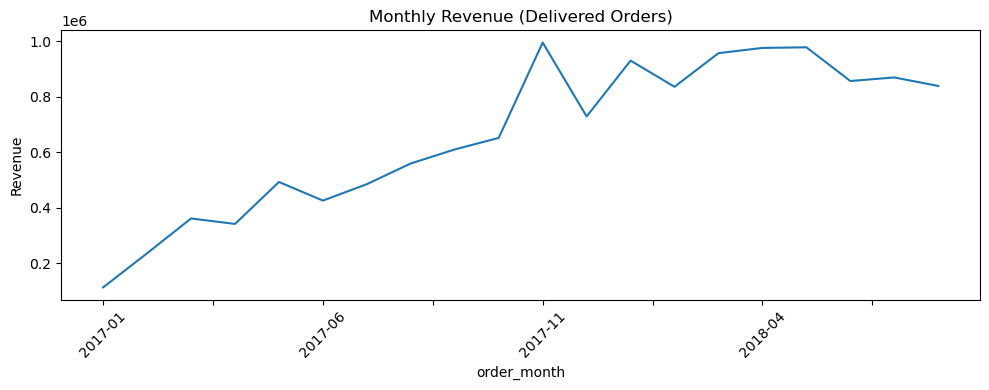

In [12]:
import matplotlib.pyplot as plt
import pandas as pd
from pathlib import Path

project = Path("C:/Users/VICTUS/OneDrive/Documents/olist-ecommerce-analysis")
images = project / "images"
images.mkdir(exist_ok=True)

monthly = (df[df["order_month"] >= "2017-01"]
           .groupby("order_month")["revenue"].sum())

monthly.plot(kind="line", figsize=(10, 4), title="Monthly Revenue (Delivered Orders)")
plt.ylabel("Revenue")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(images / "monthly_revenue_bar.png")
plt.show()

In [13]:
# RFM of the customers


snapshot = df["order_purchase_timestamp"].max() +pd.Timedelta(days=1)

rfm = (df.groupby("customer_unique_id")
       .agg(recency=("order_purchase_timestamp",lambda x:(snapshot - x.max()).days),
            frequency=("order_id","nunique"),
            monetary=("revenue","sum"))
       .reset_index())
print(rfm["frequency"].value_counts().head())
print(rfm["recency"].value_counts().head())
print(rfm["monetary"].value_counts().head())

frequency
1    90549
2     2573
3      181
4       28
5        9
Name: count, dtype: int64
recency
278    821
279    703
276    410
275    390
106    356
Name: count, dtype: int64
monetary
59.9    1581
69.9    1468
49.9    1316
89.9    1132
99.9    1109
Name: count, dtype: int64


In [14]:
def segment(R):
    
    if R.frequency >= 2 and R.recency <=180: return "Champions"
    if R.frequency >= 2 :                    return "Loyal"
    if R.recency <= 90:                      return "new/ Promising"
    if R.recency <= 270:                     return "AT-Risk"
    return "Lost"
rfm["segment"] = rfm.apply(segment, axis=1)

summary =(rfm.groupby("segment")
          .agg(customers=("customer_unique_id", "count"),
               revenue=("monetary", "sum"),
               avg_spend=("monetary", "mean"))
          .round(0).sort_values("customers",ascending=True))
summary["pct_customers"] = (100* summary["customers"]/summary["customers"].sum()).round(1)
summary["pct_revenue"] = (100 * summary["revenue"] / summary["revenue"].sum()).round(1)
print(summary)

                customers    revenue  avg_spend  pct_customers  pct_revenue
segment                                                                    
Champions            1235   341995.0      277.0            1.3          2.6
Loyal                1566   436463.0      279.0            1.7          3.3
new/ Promising      17839  2473158.0      139.0           19.1         18.6
Lost                35769  4999651.0      140.0           38.3         37.7
AT-Risk             36941  5027320.0      136.0           39.6         37.9


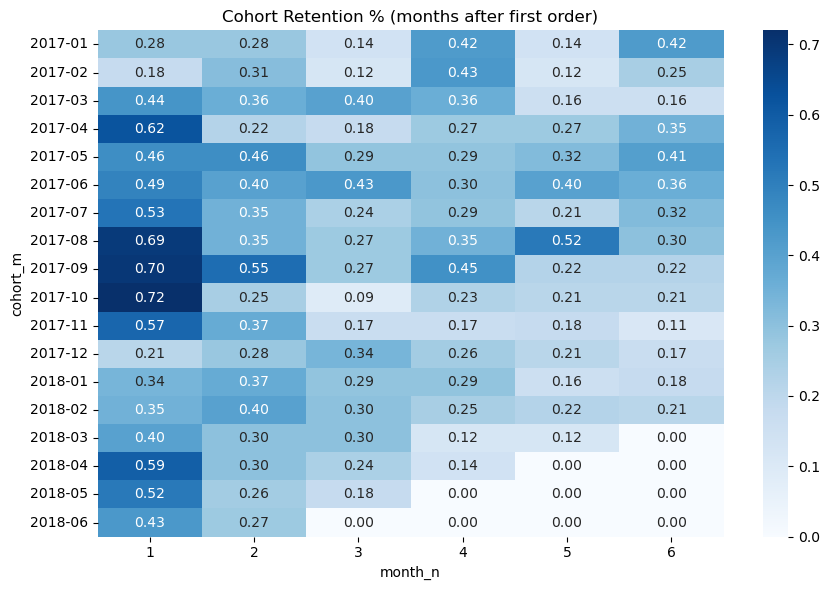

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

project = Path("C:/Users/VICTUS/OneDrive/Documents/olist-ecommerce-analysis")
images = project / "images"
images.mkdir(exist_ok=True)
d = df[["customer_unique_id", "order_purchase_timestamp"]].copy()
d["order_m"] = d["order_purchase_timestamp"].dt.to_period("M")
d["cohort_m"] = d.groupby("customer_unique_id")["order_m"].transform("min")
d["month_n"] = (d['order_m'] - d["cohort_m"]).apply(lambda x:x.n)
cohort =  (d.groupby(["cohort_m","month_n"])["customer_unique_id"]
           .nunique().unstack(fill_value=0))
retention = cohort.divide(cohort[0], axis=0).round(4) * 100
retention = retention.loc["2017-01":"2018-06",0:6]
plt.figure(figsize=(9, 6))
sns.heatmap(retention.iloc[:, 1:], annot=True, fmt=".2f", cmap="Blues")
plt.title("Cohort Retention % (months after first order)")
plt.tight_layout()
plt.savefig(images / "cohort_retention_bar.png")
plt.show()

In [ ]:
print("df" in globals())

               delivery_days  days_late  review_score
delivery_days           1.00       0.39         -0.23
days_late               0.39       1.00         -0.31
review_score           -0.23      -0.31          1.00
         count  mean
is_late             
False    89944  4.29
True      6409  2.27


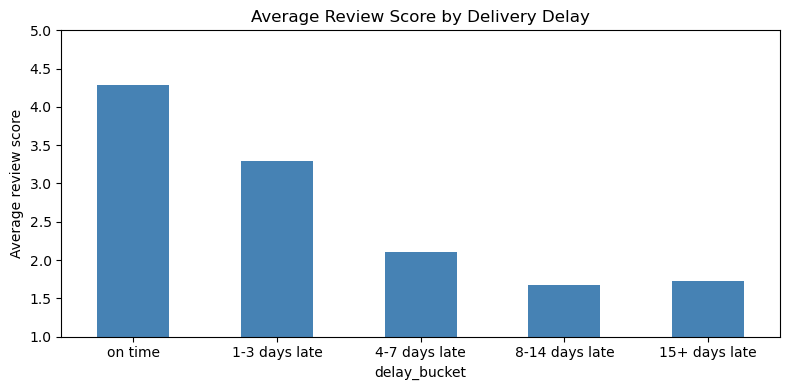

delay_bucket
On time           4.29
1-3 days late     3.29
4-7 days late     2.10
8-14 days late    1.68
15+ days late     1.72
Name: review_score, dtype: float64


In [28]:
r = df.dropna(subset=["review_score"])
print(r[["delivery_days","days_late", "review_score"]].corr(method="spearman").round(2))
print(r.groupby("is_late")["review_score"].agg(["count", "mean"]).round(2))
r = r.assign(delay_bucket=pd.cut(r["days_late"],[-1,0,3,7,14,1000],
             labels=["on time","1-3 days late", "4-7 days late", "8-14 days late","15+ days late"]))
bucket = r.groupby("delay_bucket", observed=True)["review_score"].mean().round(2)
bucket.plot(kind="bar", color="steelblue", figsize=(8, 4), title="Average Review Score by Delivery Delay")
plt.ylabel("Average review score")
plt.xticks(rotation=0)
plt.ylim(1, 5)
plt.tight_layout()
plt.savefig(images / "Average_review_bar.png")
plt.show()
r = df.dropna(subset=["review_score"])
r = r.assign(delay_bucket=pd.cut(r["days_late"], [-1, 0, 3, 7, 14, 1000],
             labels=["On time", "1-3 days late", "4-7 days late",
                     "8-14 days late", "15+ days late"]))
print(r.groupby("delay_bucket", observed=True)["review_score"].mean().round(2))

In [18]:
df = orders[orders["order_status"] == "delivered"].copy()
df = df.dropna(subset=["order_delivered_customer_date"])

purchase  = df["order_purchase_timestamp"].dt.normalize()
delivered = df["order_delivered_customer_date"].dt.normalize()
estimated = df["order_estimated_delivery_date"].dt.normalize()

df["order_month"]   = df["order_purchase_timestamp"].dt.to_period("M").astype(str)
df["delivery_days"] = (delivered - purchase).dt.days
df["is_late"]       = delivered > estimated
df["days_late"]     = (delivered - estimated).dt.days.clip(lower=0)

df = (df.merge(customers, on="customer_id", how="left")
        .merge(order_rev, on="order_id", how="left")
        .merge(reviews[["order_id", "review_score"]], on="order_id", how="left"))

print(df[["delivery_days", "is_late", "days_late", "revenue", "review_score"]].head())

   delivery_days  is_late  days_late  revenue  review_score
0              8    False          0    29.99           4.0
1             14    False          0   118.70           4.0
2              9    False          0   159.90           5.0
3             14    False          0    45.00           5.0
4              3    False          0    19.90           5.0


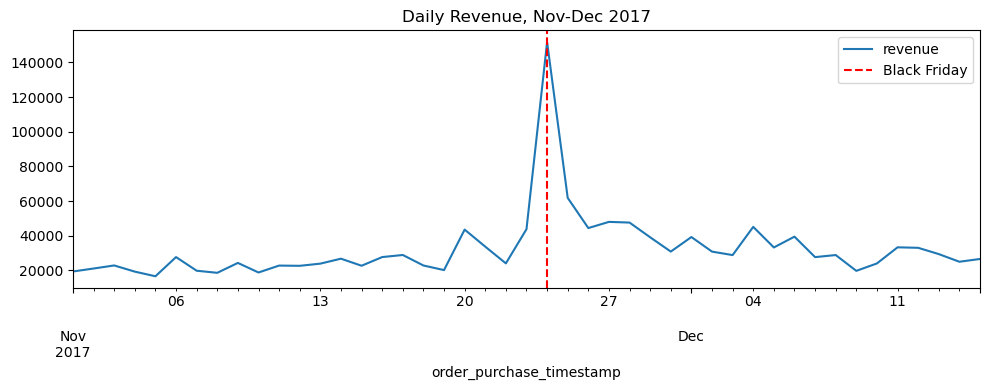

In [19]:
daily = (df.groupby(df["order_purchase_timestamp"].dt.date)["revenue"].sum())
daily.index = pd.to_datetime(daily.index)
window =daily["2017-11-01":"2017-12-15"]
window.plot(figsize=(10, 4), title="Daily Revenue, Nov-Dec 2017")
plt.axvline(pd.Timestamp("2017-11-24"), color="red", linestyle="--", label="Black Friday")
plt.legend()
plt.tight_layout()
plt.savefig(images / "Daily_revenue_bar.png")
plt.show()

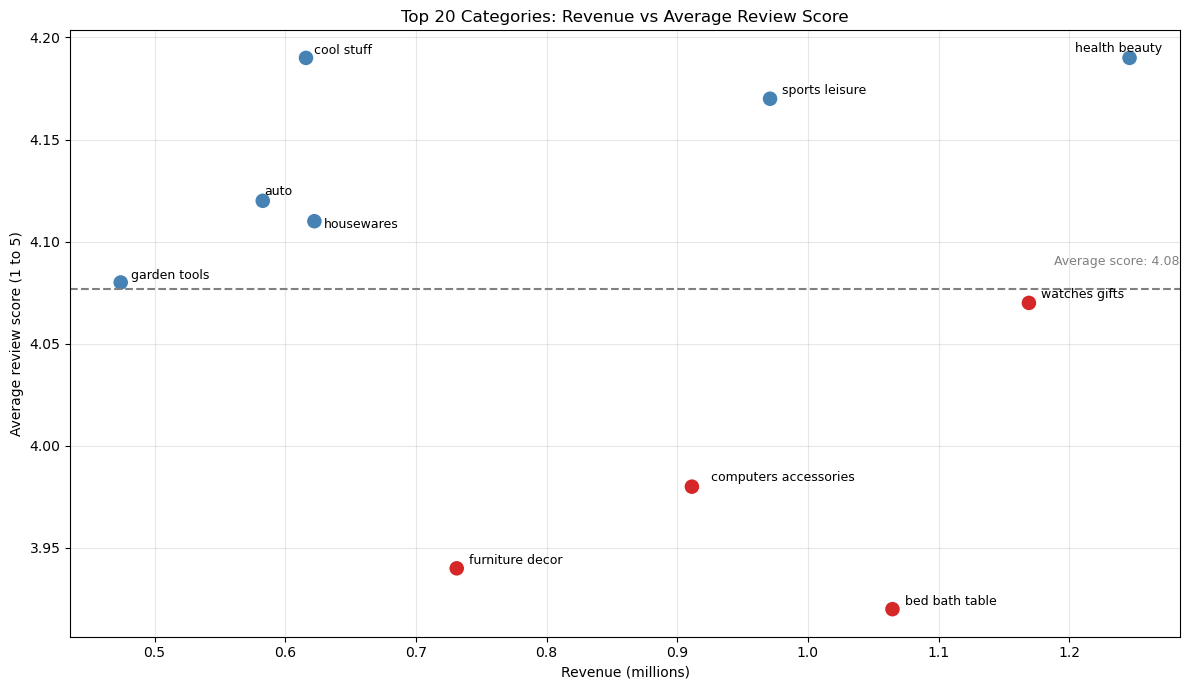

In [21]:
!pip install adjustText
from pathlib import Path
from adjustText import adjust_text

images = Path("C:/Users/VICTUS/OneDrive/Documents/olist-ecommerce-analysis/images")
images.mkdir(exist_ok=True)

# Prepare data
plot_df = top.copy()
plot_df["revenue_m"] = plot_df["revenue"] / 1e6          # revenue in millions
avg = plot_df["avg_score"].mean()
plot_df["below_avg"] = plot_df["avg_score"] < avg        # True = worse than average

# Draw
fig, ax = plt.subplots(figsize=(12, 7))
sns.scatterplot(data=plot_df, x="revenue_m", y="avg_score",
                hue="below_avg",
                palette={True: "tab:red", False: "steelblue"},
                s=130, legend=False, ax=ax)

# Labels (spaced so they don't overlap)
texts = [ax.text(r.revenue_m, r.avg_score, r.category.replace("_", " "), fontsize=9)
         for r in plot_df.itertuples()]
adjust_text(texts, arrowprops=dict(arrowstyle="-", color="gray", lw=0.5))

# Average line with a label
ax.axhline(avg, color="gray", linestyle="--")
ax.text(ax.get_xlim()[1], avg + 0.01, f"Average score: {avg:.2f}",
        ha="right", va="bottom", color="gray", fontsize=9)

ax.set_xlabel("Revenue (millions)")
ax.set_ylabel("Average review score (1 to 5)")
ax.set_title("Top 20 Categories: Revenue vs Average Review Score")
ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(images / "category_revenue_vs_rating.png", dpi=150)
plt.show()

In [ ]:
rfm.to_csv("../data/cleaned/rfm.csv", index=False)
retention.to_csv("../data/cleaned/cohort_retention.csv")
cat.to_csv("../data/cleaned/category_summary.csv", index=False)

In [ ]:
from pathlib import Path

project = Path("C:/Users/VICTUS/OneDrive/Documents/olist-ecommerce-analysis")
cleaned = project / "Data" / "cleaned"
cleaned.mkdir(parents=True, exist_ok=True)

rfm.to_csv(cleaned / "rfm.csv", index=False)
retention.to_csv(cleaned / "cohort_retention.csv")
cat.to_csv(cleaned / "category_summary.csv", index=False)

In [22]:
from pathlib import Path

cleaned = Path("C:/Users/VICTUS/OneDrive/Documents/olist-ecommerce-analysis/Data/cleaned")
cleaned.mkdir(parents=True, exist_ok=True)

outputs = {
    "rfm.csv": (rfm, False),
    "cohort_retention.csv": (retention, True),
    "category_summary.csv": (cat, False),
}

for name, (frame, keep_index) in outputs.items():
    try:
        frame.to_csv(cleaned / name, index=keep_index)
        print("saved:", name)
    except PermissionError:
        print("BLOCKED:", name, "- close it in Excel or pause OneDrive")

saved: rfm.csv
saved: cohort_retention.csv
saved: category_summary.csv


In [24]:
from pathlib import Path

output_dir = Path(r"C:\Users\VICTUS\data\cleaned")

output_dir.mkdir(parents=True, exist_ok=True)

df.to_csv(output_dir / "orders_clean.csv", index=False)

items_clean = (
    items.merge(
        products[["product_id", "category"]],
        on="product_id",
        how="left"
    )
    .merge(
        df[["order_id", "order_month", "customer_state"]],
        on="order_id",
        how="inner"
    )
)

items_clean.to_csv(output_dir / "items_clean.csv", index=False)

print("Both CSV files saved successfully!")

Both CSV files saved successfully!


In [26]:
print(round(retention[1].max(), 2))

0.72


In [27]:
o = df.sort_values("order_purchase_timestamp").copy()
o["order_n"] = o.groupby("customer_unique_id").cumcount()
first  = o[o.order_n == 0].set_index("customer_unique_id")["order_purchase_timestamp"]
second = o[o.order_n == 1].set_index("customer_unique_id")["order_purchase_timestamp"]
gap_days = (second - first.reindex(second.index)).dt.days
print(gap_days.describe())

count    2891.000000
mean       78.156347
std       108.995856
min         0.000000
25%         0.000000
50%        25.000000
75%       121.000000
max       608.000000
Name: order_purchase_timestamp, dtype: float64
